In [ ]:
import pandas as pd
import numpy as np

flower_df = pd.read_csv("../data/processed/iris_cleaned.csv")

# Classifier Modeling

In [2]:
#Define the features and target variable
x = flower_df.drop("species", axis=1)
y = flower_df["species"]

In [6]:
#Check the shape of the features and target variable

print("Features shape:", x.shape)
print("Target variable shape:", y.shape)


Features shape: (149, 4)
Target variable shape: (149,)


In [ ]:
#Split the dataset into training and testing sets

from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    x, 
    y, 
    test_size=0.2, 
    random_state=42, 
    stratify=y
)

#stratify=y ensures the species proportions remain approximately consistent between the two sets.

In [8]:
#Check the shape of the training and testing sets

print("Training features shape:", x_train.shape)
print("Training target variable shape:", y_train.shape)
print("Testing features shape:", x_test.shape)
print("Testing target variable shape:", y_test.shape)

Training features shape: (119, 4)
Training target variable shape: (119,)
Testing features shape: (30, 4)
Testing target variable shape: (30,)


In [10]:
# Feature Scaling

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

StandardScaler is a feature-scaling technique that transforms numerical features to have a mean of approximately 0 and a standard deviation of 1. In our Iris classification project, it is useful for algorithms such as Logistic Regression and K-Nearest Neighbors (KNN), which are sensitive to differences in feature scales. However, it is generally unnecessary for Decision Trees and Random Forests. To prevent data leakage, we fit the scaler on the training data and use the same transformation on the test data.

In [11]:
#Train baseline model and predict on the test set

from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)

model.fit(x_train_scaled, y_train)

y_pred = model.predict(x_test_scaled)

In [ ]:
# Evaluate the model's performance using accuracy score 

from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

Accuracy: 0.9333333333333333


An accuracy score of 93% is decent, but we cannot rely on it fully. We need to evaluate the model using other metrics like F1-score, precision, recall, and confusion matrix.

In [13]:
# Full classification report showcasing precision, recall, and F1-score for each class

from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



INTERPRETATION

-> Accuracy = 0.93 means the model correctly classified 28 out of 30 test samples. This is a strong result for a beginner classification project.

-> The model performed perfectly on setosa: all 10 setosa samples were correctly identified. For versicolor and virginica, the model was good but not perfect: it got 9 out of 10 correct for each class.

-> Precision tells us how many predicted positives were actually correct.
For versicolor and virginica, 90% of the predictions for those classes were correct. Recall tells us how many actual positives were captured. Again, 90% for versicolor and virginica, meaning the model missed 1 sample in each class. F1-score combines precision and recall into one number.
0.90 for both versicolor and virginica indicates a balanced but slightly weaker performance than setosa.

-> Macro average = 0.93 means the average performance across the three classes is 93%. Weighted average = 0.93 also reflects this because the test set is balanced (10 samples per class).

Overall conclusion:

The classifier is highly effective and shows strong separation between the species. The main weakness is confusion between versicolor and virginica, while setosa is perfectly classified. The model is reliable for this dataset, with 93% overall accuracy and no errors on setosa.

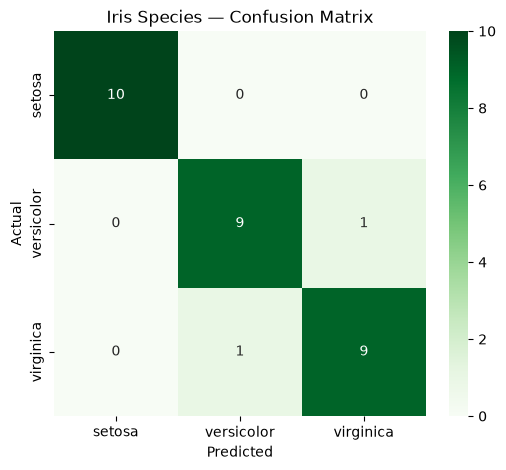

In [16]:
# Confusion Matrix to visualize the performance of the model

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=model.classes_,
    yticklabels=model.classes_
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Iris Species — Confusion Matrix")

plt.show()

INTERPRETATION

- The diagonal values represent the correctly classified samples.
- Setosa: 10 out of 10 were correctly classified.
- Versicolor: 9 out of 10 were correctly classified; 1 sample was misclassified as virginica.
- Virginica: 9 out of 10 were correctly classified; 1 sample was misclassified as versicolor.
- Overall, the model achieved an accuracy of 93% (28 out of 30 correctly classified).

This indicates that the classifier performs very well overall. The main confusion is between versicolor and virginica, which is expected because these two species are visually similar. Setosa is perfectly separated from the other classes.